# EXP-006 — MLP baseline mặc định

### Người thực hiện: Phạm Quỳnh Như
### Ngày tạo notebook: 13/11
### Loại thực nghiệm dự kiến: rerun — chạy lại bằng runner dùng chung
### Trạng thái: đang chuẩn bị chạy
Bài toán: Multiclass và Binary.




## Câu hỏi nghiên cứu và giả thuyết

### 1.Câu hỏi:MLP mặc định dự đoán ba trạng thái Baseline/Stress/Amusement và phân biệt Stress/Non-stress trên người chưa xuất hiện trong tập huấn luyện như thế nào?

### 2.Giả thuyết cần kiểm chứng: chất lượng dự đoán có thể khác nhau giữa các lớp và giữa các subject , điểm nhị phân cao chưa chắc đi kèm khả năng phân biệt tốt cả ba trạng thái.



## 1.Dữ liệu và kiểm tra môi trường

Dùng bộ physiological68, 68 feature , ghi đường dẫn, schema, số dòng, subject, target và SHA-256 thực tế sau khi kiểm tra.




In [ ]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import hashlib
import json

ROOT = Path(
    r"C:\Users\LEGION\Desktop\github\Machine-learning"
    r"\wesad-stress-detection"
)

DATA = ROOT / "data/features/g2_physiological68_group15_20261107/all_subjects.csv"
SCHEMA = DATA.parent / "feature_schema.json"

print("Thời điểm kiểm tra:",
      datetime.now(timezone(timedelta(hours=7))).isoformat())

assert DATA.is_file(), f"Không tìm thấy dữ liệu: {DATA}"
assert SCHEMA.is_file(), f"Không tìm thấy schema: {SCHEMA}"

schema = json.loads(SCHEMA.read_text(encoding="utf-8"))
features = schema["feature_columns"]
assert len(features) == 68, "Số feature không đúng 68."

checksum = hashlib.sha256(DATA.read_bytes()).hexdigest()
expected = "2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba"
assert checksum == expected, "Dữ liệu khác bộ đã thống nhất."

print("Số feature:", len(features))
print("SHA-256:", checksum)
print("Kiểm tra đầu vào đạt. Chưa huấn luyện mô hình.")

: 

In [ ]:
import pandas as pd
from IPython.display import display

frame = pd.read_csv(
    DATA,
    dtype={"subject_id": str, "window_id": str}
)

# Kiểm tra cấu trúc cơ bản.
assert frame["subject_id"].nunique() == 15
assert frame["label_original"].isin([1, 2, 3]).all()
assert not frame.duplicated(["subject_id", "window_id"]).any()

print("Số dòng dữ liệu:", len(frame))
print("Tổng số cột:", len(frame.columns))
print("Số cột feature:", len(features))
print("Số subject:", frame["subject_id"].nunique())

# Đếm số mẫu thuộc từng lớp của mỗi người.
distribution = pd.crosstab(
    frame["subject_id"],
    frame["label_original"]
).rename(columns={
    1: "Baseline",
    2: "Stress",
    3: "Amusement"
})

display(distribution)

# Kiểm tra cách chia cho lượt quick S4.
train_mask = frame["subject_id"] != "S4"
test_mask = frame["subject_id"] == "S4"

print("Số người train:",
      frame.loc[train_mask, "subject_id"].nunique())
print("Số người test:",
      frame.loc[test_mask, "subject_id"].nunique())
print("Số mẫu train:", int(train_mask.sum()))
print("Số mẫu test:", int(test_mask.sum()))

missing = frame[features].isna().sum().sum()
print("Số ô feature bị thiếu:", int(missing))

### nhận xét dữ liêu (13/11)
15 subject đều có cả 3 lớp nhưng phân bố không được cân bằng => không nên chỉ dựa vào accuracy 

s4 được làm test với 404 mẫu : 222 baseline , 117 stress và 65 amusement 

tập train 5785 mẫu là thuộc về 14 người còn lại

feature vẫn còn thiếu 37460 ô => sẽ xử lí sau 

=> tạm thời đã thực hiện kiểm tra cấu trúc nhưng vẫn cần lưu ý những hạn chế chưa được xử lí nên bước này vẫn chưa đánh giá được chất lượng mlp

##   2.đánh giá protocol

sử dụng LOSO sử dụng 1 subject để làm test và để 14 subject còn lại làm train 

đánh giá đầy đủ sẽ lặp lại đủ 15 subject , mỗi người sẽ được làm test 1 lần 

chỉ gồm 68 feature theo schema

không tuning, feature selection hoặc balancing trong EXP-006

nếu đủ 15 người rồi thì tính trung bình và độ lệch chuẩn mẫu của điểm theo người 



## 3.Cấu hình

sử dụng pipeline dùng chung của project 

giữ tham số mặc định để train

chỉ đặt random_state = 42.

không tuning , balancing hoặc feature selection


In [ ]:
import subprocess
import json
import pandas as pd
from IPython.display import display

TRAIN_PYTHON = ROOT / ".venv-g1/Scripts/python.exe"
assert TRAIN_PYTHON.is_file(), "Không tìm thấy Python dùng để train."

# Đọc pipeline bằng đúng môi trường train.
# Đoạn này chỉ tạo/kiểm tra cấu hình, không gọi fit().
inspect_code = """
import sys
import json
import sklearn
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))

from wesad.utils import read_config
from wesad.models import build_pipeline

config = read_config("configs/defaults.yaml")
config["models"] = ["mlp"]

pipeline = build_pipeline("mlp", config)

info = {
    "python": sys.version.split()[0],
    "sklearn": sklearn.__version__,
    "seed": config["seed"],
    "tasks": config["tasks"],
    "nested": config.get("nested", False),
    "balance": config.get("balance", False),
    "pipeline_steps": list(pipeline.named_steps),
    "imputer_strategy": pipeline["imputer"].strategy,
    "keep_empty_features": pipeline["imputer"].keep_empty_features,
    "mlp_parameters": pipeline["model"].get_params()
}

print(json.dumps(info))
"""

result = subprocess.run(
    [str(TRAIN_PYTHON), "-c", inspect_code],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=True,
)

config_info = json.loads(result.stdout)

print("Python dùng để train:", config_info["python"])
print("scikit-learn:", config_info["sklearn"])
print("Các bước pipeline:", config_info["pipeline_steps"])
print("Imputer:", config_info["imputer_strategy"])
print("Giữ cột bị thiếu toàn bộ trong train:",
      config_info["keep_empty_features"])
print("Các bài toán:", config_info["tasks"])
print("Tuning:", config_info["nested"])
print("Balancing:", config_info["balance"])

display(pd.DataFrame.from_dict(
    config_info["mlp_parameters"],
    orient="index",
    columns=["Giá trị thực tế"]
))

print("Đã đọc cấu hình. Chưa huấn luyện mô hình.")


## 4.Thực thi


In [ ]:
import json
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score

RUN_DEBUG = True # Đổi True để chạy thử MLP mặc định trên S4, False để chỉ kiểm tra cấu hình.

if RUN_DEBUG:
    frame = pd.read_csv(DATA)
    schema = json.loads(SCHEMA.read_text(encoding="utf-8"))
    features = schema["feature_columns"]

    train = frame["subject_id"] != "S4"
    test = frame["subject_id"] == "S4"

    X_train = frame.loc[train, features]
    y_train = frame.loc[train, "label_original"]
    X_test = frame.loc[test, features]
    y_test = frame.loc[test, "label_original"]

    debug_mlp = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True,
        )),
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(100,),
            activation="relu",
            max_iter=200,
            random_state=42,
        )),
    ])

    debug_mlp.fit(X_train, y_train)
    predicted = debug_mlp.predict(X_test)

    print("Macro-F1:", f1_score(
        y_test,
        predicted,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0,
    ))
else:
    print("Chưa chạy mlp . Đặt RUN_DEBUG=True để thực hiện.")

### nhận xét lỗi mlp(13/11)
chạy lần 1

hiện tượng : chương trình dừng tại bước fit() của MLP 

lí do : do giá trị activation="ReLU" không được chấp nhận , tên giá trị tham số phân biệt chữ hoa và chữ thường 

cách xử lí : sửa thành relu 

đã sửa và chạy lần 2 

kết quả sau khi chạy : chạy ra macro f1 


## 5. Kết quả trên s4

 phân tích mô hình đã huấn luyện ở mục 4 khỏi train lại 

In [ ]:
import sys
import sklearn
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)

# Kiểm tra MLP đã được fit.
model = debug_mlp.named_steps["model"]
assert hasattr(model, "classes_"), "MLP chưa được huấn luyện."
assert X_test.index.equals(y_test.index)

# Chỉ dự đoán bằng mô hình đã fit, không train lại.
predicted = debug_mlp.predict(X_test)

labels = [1, 2, 3]
names = ["Baseline", "Stress", "Amusement"]

results = pd.DataFrame([{
    "model": "MLP",
    "task": "multiclass",
    "outer_test": "S4",
    "n_test": len(y_test),
    "macro_f1": f1_score(
        y_test, predicted,
        labels=labels, average="macro", zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, predicted
    ),
}])

print("BẢNG ĐIỂM NGOÀI MẪU")
display(results)

report = classification_report(
    y_test,
    predicted,
    labels=labels,
    target_names=names,
    output_dict=True,
    zero_division=0,
)

print("KẾT QUẢ TỪNG LỚP")
display(pd.DataFrame(report).T)

matrix = confusion_matrix(y_test, predicted, labels=labels)
cm_table = pd.DataFrame(
    matrix,
    index=[f"Thật: {name}" for name in names],
    columns=[f"Đoán: {name}" for name in names],
)

print("CONFUSION MATRIX")
display(cm_table)

print("Số epoch thực tế:", model.n_iter_)
print("Train loss cuối:", model.loss_)
print("Môi trường của lượt thử:",
      sys.version.split()[0], "| sklearn:", sklearn.__version__)

### nhận xét (14/11)

MLP trên s4 chạy đạt 

macro f1 = 0,6212 | Balanced accuracy = 0,6610

Mô hình nhận đúng 222/222 mẫu Baseline, 115/117 mẫu Stress,
nhưng sai toàn bộ 65 mẫu Amusement.

Mô hình dừng ở 47 epoch, train loss khoảng 0,001012.
Loss thấp chưa đồng nghĩa dự đoán tốt trên test.

Đây mới là kết quả Multiclass của S4. Cần thống nhất
môi trường với mục 05 trước khi chốt baseline.

## 6. Hình minh họa




In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from datetime import datetime

model = debug_mlp.named_steps["model"]

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained"
)

ConfusionMatrixDisplay.from_predictions(
    y_test, predicted,
    labels=[1, 2, 3],
    display_labels=["Baseline", "Stress", "Amusement"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("MLP — Multiclass — Test S4")
axes[0].tick_params(axis="x", labelrotation=20)

loss = model.loss_curve_
axes[1].plot(range(1, len(loss) + 1), loss)
axes[1].set(
    title="Training loss — không phải loss test",
    xlabel="Epoch", ylabel="Loss"
)
axes[1].grid(alpha=0.3)

FIG_DIR = ROOT / "outputs" / (
    "EXP006_S4_figures_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
FIG_DIR.mkdir(parents=True)
fig.savefig(FIG_DIR / "confusion_matrix_and_loss.png", dpi=150)

plt.show()
print("Đã lưu hình tại:", FIG_DIR)

## 7. Phân tích

Accuracy khoảng gần 84% nhưng mô hình vẫn chưa nhận đúng mẫu amusement nào => không nên dựa vào accuracy để đánh giá chất lượng phân lớp 

khi kết quả test còn hạn chế mà lại train loss nên không thể kết luận sớm

kết quả này chỉ thuộc s4 

không tham tham số chỉ để cải thiện teat s4

## 8. Kết luận, provenance và nhật ký (14/11)

MLP đã chạy được sau khi sửa lỗi "ReLu" thành "relu" 

Vẫn còn hạn chế là chưa nhận diện đúng lớp amusement 

Nguồn kết quả: các ô thực thi và phân tích trong notebook này

Cấu hình: một lớp ẩn 100 nút, ReLU, max_iter=200, seed 42

Môi trường thực thi: Python 3.13.9, scikit-learn 1.7.2.

Dữ liệu: physiological68, đã kiểm tra SHA-256 
trạng thái lượt thử trên s4 => vẫn chưa hoàn thành exp006

Việc còn thiếu :

thống nhất môi trường 

bổ sung binary và đánh giá đủ loso 

so sánh với RF/SVM cùng điều kiện 



## 9. chạy lại trong môi trường thống nhất (14/11)

chạy lại mlp mặc định trên s4 bằng môi trường .venv-g1.
giữ nguyên dữ liệu, cách chia và tham số để đối chiếu với lượt trước.

In [1]:
import sys
import sklearn
from pathlib import Path

expected_python = Path(r"D:\venvs\wesad312\Scripts\python.exe")

print("python:", sys.version.split()[0])
print("sklearn:", sklearn.__version__)
print("đường dẫn:", sys.executable)

assert Path(sys.executable).resolve() == expected_python.resolve(), (
    "chưa chọn đúng kernel ở ổ d"
)

print("đúng môi trường để chạy lại mlp")

python: 3.12.14
sklearn: 1.9.1
đường dẫn: d:\venvs\wesad312\Scripts\python.exe
đúng môi trường để chạy lại mlp


đọc lại dữ liệu và train multiclass trên s4

In [2]:
import json
import warnings
import pandas as pd

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score

root = Path(
    r"C:\Users\LEGION\Desktop\github\Machine-learning"
    r"\wesad-stress-detection"
)
data = root / "data/features/g2_physiological68_group15_20261107"

frame = pd.read_csv(
    data / "all_subjects.csv",
    dtype={"subject_id": str}
)
schema = json.loads(
    (data / "feature_schema.json").read_text(encoding="utf-8")
)
features = schema["feature_columns"]

assert len(features) == 68
assert frame["subject_id"].nunique() == 15
assert frame["label_original"].isin([1, 2, 3]).all()

train = frame["subject_id"] != "S4"
test = frame["subject_id"] == "S4"

assert frame.loc[train, "subject_id"].nunique() == 14
assert test.any()

x_train = frame.loc[train, features]
y_train = frame.loc[train, "label_original"]
x_test = frame.loc[test, features]
y_test = frame.loc[test, "label_original"]

mlp_s4 = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )),
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(100,),
        activation="relu",
        max_iter=200,
        random_state=42
    ))
])

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    mlp_s4.fit(x_train, y_train)

pred_s4 = mlp_s4.predict(x_test)
model_s4 = mlp_s4.named_steps["model"]

print("số mẫu train:", len(y_train))
print("số mẫu test:", len(y_test))
print("macro f1:", f1_score(
    y_test, pred_s4,
    labels=[1, 2, 3],
    average="macro",
    zero_division=0
))
print("balanced accuracy:", balanced_accuracy_score(y_test, pred_s4))
print("số epoch:", model_s4.n_iter_)
print("train loss cuối:", model_s4.loss_)

print("\ncảnh báo:")
if caught:
    for item in caught:
        print(type(item.message).__name__, ":", item.message)
else:
    print("không có")

số mẫu train: 5785
số mẫu test: 404
macro f1: 0.621225978366416
balanced accuracy: 0.660968660968661
số epoch: 47
train loss cuối: 0.0010124072111406222

cảnh báo:
không có


### binary trên s4(14/11)

stress mang nhãn 1
baseline và amusement được gộp thành non-stress, mang nhãn 0.
giữ nguyên cách chia và cấu hình như lượt multiclass.

In [3]:
from sklearn.base import clone
from sklearn.metrics import classification_report

# Đổi nhãn, giữ nguyên dữ liệu và cách chia.
y_train_binary = (y_train == 2).astype(int)
y_test_binary = (y_test == 2).astype(int)

# Tạo pipeline chưa fit, có cùng cấu hình với lượt multiclass.
mlp_binary = clone(mlp_s4)

with warnings.catch_warnings(record=True) as binary_warnings:
    warnings.simplefilter("always")
    mlp_binary.fit(x_train, y_train_binary)

pred_binary = mlp_binary.predict(x_test)
model_binary = mlp_binary.named_steps["model"]

print("macro f1:", f1_score(
    y_test_binary,
    pred_binary,
    labels=[0, 1],
    average="macro",
    zero_division=0
))
print("balanced accuracy:", balanced_accuracy_score(
    y_test_binary, pred_binary
))
print("số epoch:", model_binary.n_iter_)
print("train loss cuối:", model_binary.loss_)

print("\ncảnh báo:")
if binary_warnings:
    for item in binary_warnings:
        print(type(item.message).__name__, ":", item.message)
else:
    print("không có")

print("\nkết quả từng lớp:")
print(classification_report(
    y_test_binary,
    pred_binary,
    labels=[0, 1],
    target_names=["non-stress", "stress"],
    zero_division=0
))

macro f1: 1.0
balanced accuracy: 1.0
số epoch: 42
train loss cuối: 0.0008219627842076473

cảnh báo:
không có

kết quả từng lớp:
              precision    recall  f1-score   support

  non-stress       1.00      1.00      1.00       287
      stress       1.00      1.00      1.00       117

    accuracy                           1.00       404
   macro avg       1.00      1.00      1.00       404
weighted avg       1.00      1.00      1.00       404



gom kết quả 2 bài toán trên s4 thành 1 bảng

In [4]:
from IPython.display import display

summary_s4 = pd.DataFrame([
    {
        "task": "multiclass",
        "test_subject": "S4",
        "n_test": len(y_test),
        "macro_f1": f1_score(
            y_test, pred_s4,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, pred_s4
        ),
        "epochs": model_s4.n_iter_,
        "train_loss": model_s4.loss_
    },
    {
        "task": "binary",
        "test_subject": "S4",
        "n_test": len(y_test_binary),
        "macro_f1": f1_score(
            y_test_binary, pred_binary,
            labels=[0, 1],
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_test_binary, pred_binary
        ),
        "epochs": model_binary.n_iter_,
        "train_loss": model_binary.loss_
    }
])

display(summary_s4.round(4))

,task,test_subject,n_test,macro_f1,balanced_accuracy,epochs,train_loss
0,multiclass,S4,404,0.6212,0.661,47,0.0010
1,binary,S4,404,1.0000,1.000,42,0.0008


## 10. chạy loso đủ 15 người (14/11)

đánh giá multiclass và binary trên từng người
giữ nguyên cấu hình mlp, không tuning
imputer và scaler được fit riêng trên tập train của mỗi lượt

In [5]:
from datetime import datetime
from tempfile import mkdtemp

# Mỗi lần chạy tạo thư mục riêng để giữ kết quả cũ.
output_parent = root / "outputs"
output_parent.mkdir(exist_ok=True)

run_dir = Path(mkdtemp(
    prefix=f"exp006_loso_{datetime.now():%Y%m%d}_",
    dir=str(output_parent)
))
print("thư mục kết quả:", run_dir)

subjects = sorted(
    frame["subject_id"].unique(),
    key=lambda value: int(value[1:])
)
rows = []

for task in ["multiclass", "binary"]:
    labels = [1, 2, 3] if task == "multiclass" else [0, 1]

    for subject in subjects:
        train_fold = frame["subject_id"] != subject
        test_fold = frame["subject_id"] == subject

        x_tr = frame.loc[train_fold, features]
        x_te = frame.loc[test_fold, features]
        y_tr = frame.loc[train_fold, "label_original"]
        y_te = frame.loc[test_fold, "label_original"]

        if task == "binary":
            y_tr = (y_tr == 2).astype(int)
            y_te = (y_te == 2).astype(int)

        # Clone tạo pipeline mới, không giữ mô hình đã fit.
        pipeline = clone(mlp_s4)

        with warnings.catch_warnings(record=True) as fold_warnings:
            warnings.simplefilter("always")
            pipeline.fit(x_tr, y_tr)

        pred = pipeline.predict(x_te)
        fitted = pipeline.named_steps["model"]

        rows.append({
            "task": task,
            "test_subject": subject,
            "n_train": len(y_tr),
            "n_test": len(y_te),
            "macro_f1": f1_score(
                y_te, pred,
                labels=labels,
                average="macro",
                zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(y_te, pred),
            "epochs": fitted.n_iter_,
            "train_loss": fitted.loss_,
            "warnings": " | ".join(
                f"{type(w.message).__name__}: {w.message}"
                for w in fold_warnings
            )
        })

        # Lưu sau mỗi lượt để giữ các lượt đã hoàn thành.
        pd.DataFrame(rows).to_csv(
            run_dir / "metrics_by_subject.csv",
            index=False
        )

        pd.DataFrame({
            "subject_id": subject,
            "row_index": x_te.index,
            "y_true": y_te.to_numpy(),
            "y_pred": pred
        }).to_csv(
            run_dir / f"predictions_{task}_{subject}.csv",
            index=False
        )

        print(
            f"{len(rows)}/30 — {task} — {subject} — "
            f"macro f1: {rows[-1]['macro_f1']:.4f}",
            flush=True
        )

loso_results = pd.DataFrame(rows)
print("đã hoàn thành:", len(loso_results), "/30 lượt")

thư mục kết quả: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp006_loso_20261114_sev3q2_z
1/30 — multiclass — S2 — macro f1: 0.4257
2/30 — multiclass — S3 — macro f1: 0.7230
3/30 — multiclass — S4 — macro f1: 0.6212
4/30 — multiclass — S5 — macro f1: 0.7829
5/30 — multiclass — S6 — macro f1: 0.8735
6/30 — multiclass — S7 — macro f1: 0.6969
7/30 — multiclass — S8 — macro f1: 0.6167
8/30 — multiclass — S9 — macro f1: 0.5297
9/30 — multiclass — S10 — macro f1: 0.5696
10/30 — multiclass — S11 — macro f1: 0.7276
11/30 — multiclass — S13 — macro f1: 0.5700
12/30 — multiclass — S14 — macro f1: 0.6257
13/30 — multiclass — S15 — macro f1: 0.7567
14/30 — multiclass — S16 — macro f1: 0.5498
15/30 — multiclass — S17 — macro f1: 0.6232
16/30 — binary — S2 — macro f1: 0.4331
17/30 — binary — S3 — macro f1: 0.7632
18/30 — binary — S4 — macro f1: 1.0000
19/30 — binary — S5 — macro f1: 0.8620
20/30 — binary — S6 — macro f1: 1.0000
21/30 — binary — S7 — macro f1: 0.81

kiểm tra và tính kết quả tổng hợp 

In [6]:
# Kiểm tra mỗi bài toán có đủ 15 người, mỗi người đúng một lượt.
expected_subjects = set(frame["subject_id"].unique())

assert set(loso_results["task"]) == {"multiclass", "binary"}

for task in ["multiclass", "binary"]:
    task_rows = loso_results[loso_results["task"] == task]

    assert len(task_rows) == 15, f"{task} chưa đủ 15 lượt"
    assert set(task_rows["test_subject"]) == expected_subjects
    assert not task_rows["test_subject"].duplicated().any()

# Mỗi người có trọng số như nhau.
summary_loso = loso_results.groupby("task").agg(
    n_subjects=("test_subject", "nunique"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
    balanced_accuracy_std=("balanced_accuracy", "std")
).reset_index()

print("kết quả trung bình và độ lệch chuẩn mẫu theo người:")
display(summary_loso.round(4))

print("các lượt có cảnh báo:")
warning_rows = loso_results[
    loso_results["warnings"].fillna("").ne("")
]
display(warning_rows[
    ["task", "test_subject", "epochs", "warnings"]
])

summary_loso.to_csv(run_dir / "summary.csv", index=False)
print("đã lưu bảng tổng hợp tại:", run_dir / "summary.csv")


kết quả trung bình và độ lệch chuẩn mẫu theo người:


,task,n_subjects,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,binary,15,0.7986,0.1846,0.8225,0.1671
1,multiclass,15,0.6462,0.1144,0.6815,0.1050


các lượt có cảnh báo:


,task,test_subject,epochs,warnings


đã lưu bảng tổng hợp tại: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp006_loso_20261114_sev3q2_z\summary.csv


### kết quả loso theo từng người

so sánh macro f1 và balanced accuracy giữa 15 người
cho hai bài toán multiclass và binary

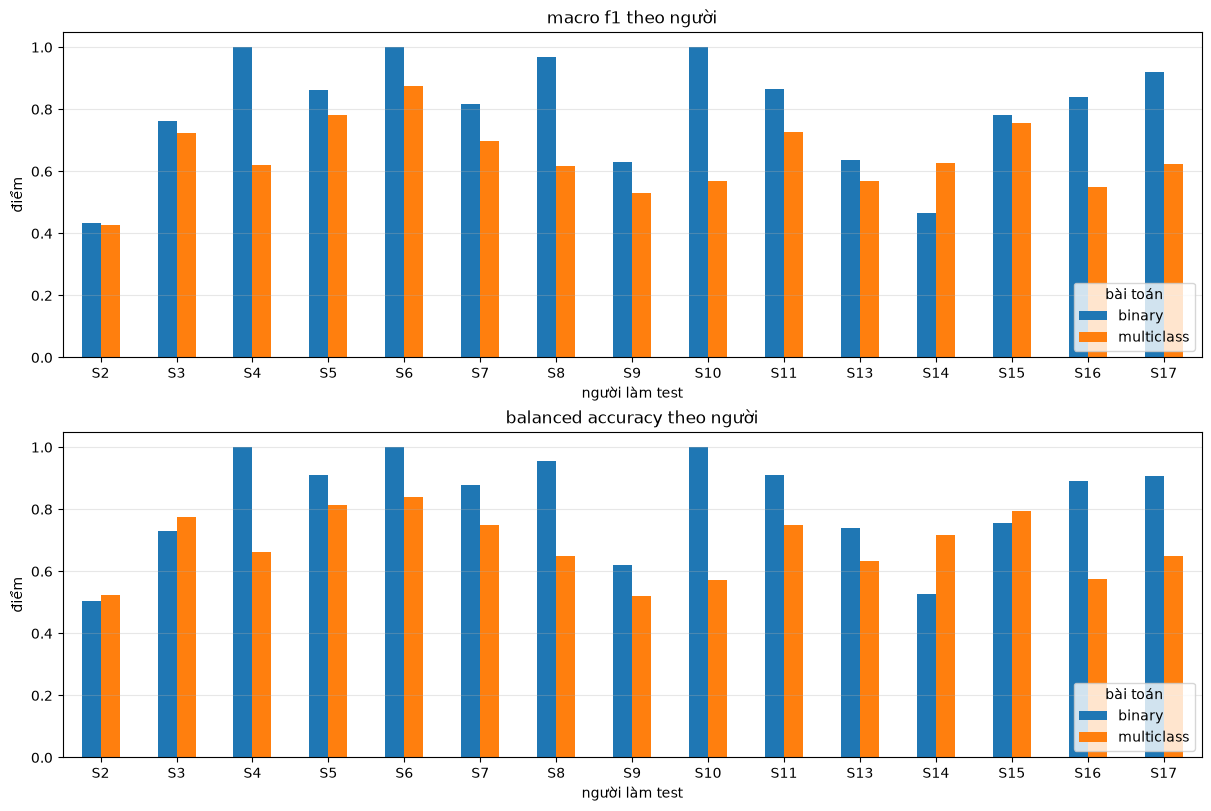

đã lưu hình: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp006_loso_20261114_sev3q2_z\loso_by_subject.png


In [7]:
import matplotlib.pyplot as plt

subject_order = sorted(
    loso_results["test_subject"].unique(),
    key=lambda value: int(value[1:])
)

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), layout="constrained"
)

for ax, metric, title in zip(
    axes,
    ["macro_f1", "balanced_accuracy"],
    ["macro f1 theo người", "balanced accuracy theo người"]
):
    table = loso_results.pivot(
        index="test_subject",
        columns="task",
        values=metric
    ).reindex(subject_order)

    table.plot.bar(ax=ax, rot=0)
    ax.set_title(title)
    ax.set_xlabel("người làm test")
    ax.set_ylabel("điểm")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="bài toán", loc="lower right")

figure_path = run_dir / "loso_by_subject.png"
fig.savefig(figure_path, dpi=150)
plt.show()

print("đã lưu hình:", figure_path)

lưu cấu hình và môi trường thực tế

In [9]:
import sys
import json
import hashlib
import sklearn
import numpy as np
from datetime import datetime

data_file = data / "all_subjects.csv"

run_info = {
    "experiment": "EXP-006",
    "ngay_luu": datetime.now().strftime("%d/%m/%Y"),
    "nguoi_thuc_hien": "như",
    "python": sys.version.split()[0],
    "python_path": sys.executable,
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "data_path": str(data_file),
    "data_sha256": hashlib.sha256(
        data_file.read_bytes()
    ).hexdigest(),
    "features": features,
    "validation": "loso",
    "tasks": ["multiclass", "binary"],
    "binary_labels": {
        "non-stress": 0,
        "stress": 1
    },
    "pipeline": {
        "imputer": mlp_s4.named_steps["imputer"].get_params(),
        "scaler": mlp_s4.named_steps["scaler"].get_params(),
        "mlp": mlp_s4.named_steps["model"].get_params()
    },
    "completed_folds": len(loso_results)
}

# Ghi NaN thành chuỗi mô tả trong file cấu hình.
# Không thay đổi imputer hay dữ liệu đã train.
run_info["pipeline"]["imputer"]["missing_values"] = "NaN"

config_path = run_dir / "run_info.json"

config_path.write_text(
    json.dumps(
        run_info,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

# Kiểm tra file vừa lưu đọc lại được.
saved_info = json.loads(config_path.read_text(encoding="utf-8"))

print("đã lưu cấu hình:", config_path)
print("số lượt hoàn thành:", saved_info["completed_folds"], "/30")

đã lưu cấu hình: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp006_loso_20261114_sev3q2_z\run_info.json
số lượt hoàn thành: 30 /30


## nhận xét kết quả (14/11) 
đã chạy đủ 15 lượt loso cho mỗi bài toánh , tổng cộng 30 lượt

| bài toán | macro f1 trung bình ± độ lệch chuẩn | balanced accuracy trung bình ± độ lệch chuẩn |
|---|---|---|
| multiclass | 0,6462 ± 0,1144 | 0,6815 ± 0,1050 |
| binary | 0,7986 ± 0,1846 | 0,8225 ± 0,1671 |


binary đạt điểm trung bình cao hơn multiclass trong lần chạy này và độ lệch chuẩn cũng lớn hơn, kết quả còn khác nhau giữa các người 


trên s4, binary đạt điểm 1,0 nhưng multiclass chưa nhận đúng
65 mẫu amusement. vì vậy điểm binary cao chưa chứng minh mô hình
phân biệt tốt cả ba trạng thái.

không ghi nhận cảnh báo trong 30 lượt fit.
train loss thấp chưa đảm bảo dự đoán tốt trên người chưa gặp.

lỗi khi lưu cấu hình:

json không nhận giá trị nan trong tham số missing_values của imputer.

đã sửa cách biểu diễn giá trị này thành chuỗi "NaN" trong file cấu hình.
=> thay đổi này không làm thay đổi mô hình hay kết quả đã train

kiểm tra các file kết quả đã lưu có đủ và khớp nhau không

In [10]:
import numpy as np

required_files = [
    "metrics_by_subject.csv",
    "summary.csv",
    "loso_by_subject.png",
    "run_info.json"
]

for name in required_files:
    assert (run_dir / name).is_file(), f"thiếu file: {name}"

metrics = pd.read_csv(run_dir / "metrics_by_subject.csv")

assert len(metrics) == 30, "chưa đủ 30 lượt"
assert not metrics.duplicated(["task", "test_subject"]).any()

for task in ["multiclass", "binary"]:
    task_metrics = metrics[metrics["task"] == task]

    assert len(task_metrics) == 15
    assert set(task_metrics["test_subject"]) == set(subjects)

    for subject in subjects:
        path = run_dir / f"predictions_{task}_{subject}.csv"
        assert path.is_file(), f"thiếu file: {path.name}"

        predictions = pd.read_csv(path)
        expected_count = int((frame["subject_id"] == subject).sum())
        assert len(predictions) == expected_count

        labels = [1, 2, 3] if task == "multiclass" else [0, 1]
        score = f1_score(
            predictions["y_true"],
            predictions["y_pred"],
            labels=labels,
            average="macro",
            zero_division=0
        )

        recorded = task_metrics.loc[
            task_metrics["test_subject"] == subject, "macro_f1"
        ].iloc[0]

        assert np.isclose(score, recorded), (
            f"điểm không khớp: {task}, {subject}"
        )

print("đủ file kết quả")
print("đủ 15 người cho mỗi bài toán")
print("macro f1 tính lại từ dự đoán khớp bảng điểm")
print("thư mục:", run_dir)

đủ file kết quả
đủ 15 người cho mỗi bài toán
macro f1 tính lại từ dự đoán khớp bảng điểm
thư mục: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp006_loso_20261114_sev3q2_z
